`## Setup and GPU check

In [8]:
%pip install -q ultralytics

import os, json, random, shutil, collections
from pathlib import Path

import torch, cv2
import matplotlib.pyplot as plt

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

if "OUT" in globals():
    print("OUT:", OUT)
    print("train images:", len(list((OUT / "images" / "train").glob("*.png"))))
    print("val images:  ", len(list((OUT / "images" / "val").glob("*.png"))))
    print("data.yaml exists:", (OUT / "data.yaml").exists())
else:
    print("Dataset paths are defined in the next cell; run cells in order.")

Note: you may need to restart the kernel to use updated packages.
CUDA available: True
GPU: Tesla T4
OUT: /kaggle/working/doclaynet_yolo
train images: 0
val images:   0
data.yaml exists: False


## Paths and sanity check

In [9]:
ROOT = Path("/kaggle/input/datasets/dlaproj123/doclaynet")
COCO = ROOT / "COCO"
PNG  = ROOT / "PNG"
OUT  = Path("/kaggle/working/doclaynet_yolo")

print("COCO files:", sorted(os.listdir(COCO)))
print("PNG sample:", sorted(os.listdir(PNG))[:3])

# Confirm a real image from val.json exists where we expect it
val_meta = json.load(open(COCO / "val.json"))
first = val_meta["images"][0]["file_name"]
print("First image exists in PNG/:", (PNG / first).exists())
del val_meta

COCO files: ['test.json', 'train.json', 'val.json']
PNG sample: ['000000c264503f54eea3adfd8fabafe47248c76f7d688cb8f26b4d24876fccbe.png', '0003579dd4c3ad0771c971afa45e38e60b3d21930113213974ed835198408e0b.png', '00058abe155df18b34a492150ca9dac8da2f9904888abd40ac31d04e48899c47.png']
First image exists in PNG/: True


## Config

In [10]:
random.seed(42)

NAMES = ["Caption", "Footnote", "Formula", "List-item", "Page-footer", "Page-header",
         "Picture", "Section-header", "Table", "Text", "Title"]

RARE = {1, 2, 3, 11}   # COCO ids: Caption, Footnote, Formula, Title

# split: (number of pages, fraction of pages that must contain a rare class)
CFG = {
    "train": (8000, 0.5),
    "val":   (1000, 0.0),   # keep val natural
}

## Select the subset

In [11]:
from collections import defaultdict, Counter

def select_pages(split, n_pages, rare_frac):
    d = json.load(open(COCO / f"{split}.json"))
    by_img = defaultdict(list)
    for a in d["annotations"]:
        by_img[a["image_id"]].append(a)

    if rare_frac == 0:
        # natural sample: any page, no filtering
        chosen = random.sample(d["images"], n_pages)
    else:
        rare_ids = {i for i, anns in by_img.items()
                    if any(a["category_id"] in RARE for a in anns)}
        rare = [im for im in d["images"] if im["id"] in rare_ids]
        rest = [im for im in d["images"] if im["id"] not in rare_ids]
        random.shuffle(rare); random.shuffle(rest)
        chosen = rare[: int(n_pages * rare_frac)]
        chosen += rest[: n_pages - len(chosen)]
        random.shuffle(chosen)

    anns = {im["id"]: by_img[im["id"]] for im in chosen}   # keep memory small
    return chosen, anns

selected = {s: select_pages(s, *CFG[s]) for s in CFG}

for s, (imgs, anns) in selected.items():
    cls = Counter(a["category_id"] for v in anns.values() for a in v)
    cats = Counter(im["doc_category"] for im in imgs)
    print(f"\n== {s}: {len(imgs)} pages ==")
    print("Classes:", {NAMES[k-1]: v for k, v in sorted(cls.items())})
    print("Doc categories:", dict(cats))


== train: 8000 pages ==
Classes: {'Caption': 3860, 'Footnote': 1158, 'Formula': 4024, 'List-item': 16915, 'Page-footer': 6804, 'Page-header': 5185, 'Picture': 5537, 'Section-header': 12496, 'Table': 2982, 'Text': 48221, 'Title': 836}
Doc categories: {'financial_reports': 2174, 'laws_and_regulations': 1314, 'manuals': 1543, 'patents': 582, 'scientific_articles': 2002, 'government_tenders': 385}

== val: 1000 pages ==
Classes: {'Caption': 294, 'Footnote': 89, 'Formula': 263, 'List-item': 1876, 'Page-footer': 861, 'Page-header': 1000, 'Picture': 398, 'Section-header': 2477, 'Table': 342, 'Text': 7777, 'Title': 41}
Doc categories: {'manuals': 299, 'financial_reports': 266, 'scientific_articles': 159, 'government_tenders': 47, 'laws_and_regulations': 159, 'patents': 70}


## Convert COCO to YOLO and copy images

In [12]:
def convert(split):
    imgs, anns = selected[split]
    img_dir = OUT / "images" / split
    lbl_dir = OUT / "labels" / split
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)

    for im in imgs:
        W, H = im["width"], im["height"]
        shutil.copy(PNG / im["file_name"], img_dir / im["file_name"])

        lines = []
        for a in anns[im["id"]]:
            x, y, w, h = a["bbox"]                  # COCO: top-left x, y, width, height (pixels)
            if w <= 1 or h <= 1:
                continue
            cx, cy = (x + w / 2) / W, (y + h / 2) / H   # YOLO: normalized center
            cls = a["category_id"] - 1                  # COCO ids 1..11 -> YOLO 0..10
            lines.append(f"{cls} {cx:.6f} {cy:.6f} {w / W:.6f} {h / H:.6f}")

        (lbl_dir / (Path(im["file_name"]).stem + ".txt")).write_text("\n".join(lines))
    print(split, "done:", len(imgs), "pages")

for s in CFG:
    convert(s)

train done: 8000 pages
val done: 1000 pages


In [13]:
from collections import Counter
cnt = Counter()
for f in (OUT / "labels" / "val").glob("*.txt"):
    for line in f.read_text().splitlines():
        cnt[NAMES[int(line.split()[0])]] += 1
print(dict(cnt))
assert len(cnt) == 11, "Some classes are missing from val!"

{'Page-header': 1000, 'Section-header': 2477, 'Text': 7777, 'Table': 342, 'Page-footer': 861, 'List-item': 1876, 'Formula': 263, 'Caption': 294, 'Picture': 398, 'Footnote': 89, 'Title': 41}


## Visual check

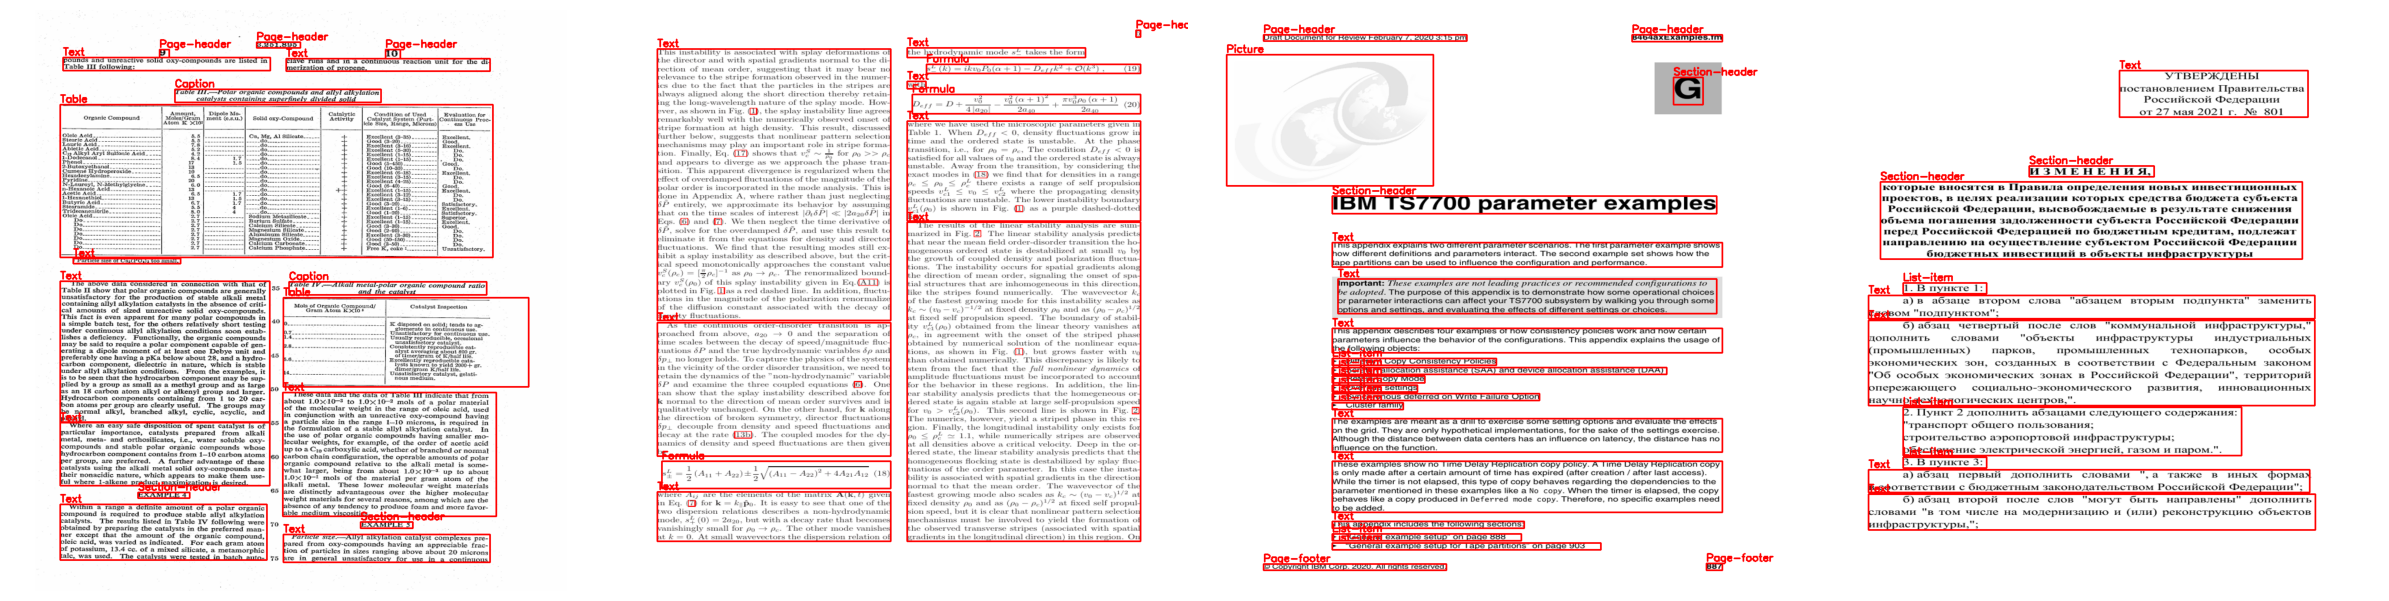

In [14]:
def show_samples(split="train", n=4):
    files = random.sample(sorted((OUT / "images" / split).glob("*.png")), n)
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 8))
    for ax, f in zip(axes, files):
        img = cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB)
        H, W = img.shape[:2]
        lbl = OUT / "labels" / split / (f.stem + ".txt")
        for line in lbl.read_text().splitlines():
            c, cx, cy, w, h = line.split()
            c = int(c); cx, cy, w, h = (float(v) for v in (cx, cy, w, h))
            x1, y1 = int((cx - w/2) * W), int((cy - h/2) * H)
            x2, y2 = int((cx + w/2) * W), int((cy + h/2) * H)
            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
            cv2.putText(img, NAMES[c], (x1, max(y1 - 4, 10)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
        ax.imshow(img); ax.axis("off")
    plt.tight_layout(); plt.show()

show_samples("train")

## Write data.yaml

In [15]:
yaml_text = f"path: {OUT}\ntrain: images/train\nval: images/val\nnames:\n"
yaml_text += "".join(f"  {i}: {n}\n" for i, n in enumerate(NAMES))
(OUT / "data.yaml").write_text(yaml_text)
print(yaml_text)

path: /kaggle/working/doclaynet_yolo
train: images/train
val: images/val
names:
  0: Caption
  1: Footnote
  2: Formula
  3: List-item
  4: Page-footer
  5: Page-header
  6: Picture
  7: Section-header
  8: Table
  9: Text
  10: Title



In [16]:
import os
print(os.path.exists("/kaggle/working/doclaynet_yolo"))
print(os.listdir("/kaggle/working"))

True
['doclaynet_yolo', 'runs', '.virtual_documents', 'yolov8s.pt']


## Train baseline (fine-tune pretrained YOLOv8s)

In [17]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")          # pretrained on COCO, head rebuilt for 11 classes

results = model.train(              # assigned to a variable so the huge metrics dump isn't printed
    data=str(OUT / "data.yaml"),
    epochs=20,
    imgsz=640,
    batch=16,
    device=0,
    workers=4,
    fliplr=0.0,                     # horizontal flips make no sense for documents
    patience=10,                    # stop early if val mAP doesn't improve for 10 epochs
    save_period=5,                  # also save a checkpoint every 5 epochs
    seed=42,
    project="/kaggle/working/runs",
    name="baseline",
    exist_ok=True,
)
model = Path("/kaggle/working/runs/baseline/weights/best.pt")
assert model.exists(), f"Model not found: {model}"

shutil.make_archive(
    "/kaggle/working/best_model",
    "zip",
    root_dir=model.parent,
    base_dir=model.name,
)
print("Created /kaggle/working/best_model.zip")

Ultralytics 8.4.201 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/doclaynet_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline, nbs=64, nms=None, opset=None, optimize=

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/20      4.63G     0.9722      1.109     0.9866        411        640: 100% ━━━━━━━━━━━━ 500/500 4.4it/s 1:550.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 2.7it/s 11.8s0.4s
                   all       1000      15418      0.627      0.603      0.656       0.43

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/20      4.65G     0.9015      1.001     0.9504        382        640: 100% ━━━━━━━━━━━━ 500/500 4.4it/s 1:540.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 3.0it/s 10.8s0.3s
                   all       1000      15418      0.663      0.645      0.684      0.463

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/20      4.65G     0.8569     0.9344     0.9333        342        640: 100% ━━━━━━━━━━━━ 500/500 4.4it/s 1:540.2sss
                 Class     I

## Evaluate baseline

Ultralytics 8.4.201 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3417.2±748.4 MB/s, size: 334.7 KB)
val: Scanning /kaggle/working/doclaynet_yolo/labels/val.cache... 1000 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 299.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 3.6it/s 17.4s0.3s
                   all       1000      15418      0.814      0.805      0.855      0.631
               Caption        180        294      0.834      0.908      0.935      0.797
              Footnote         36         89      0.728      0.361      0.507      0.353
               Formula         84        263      0.872      0.748      0.848      0.615
             List-item        236       1876      0.814      0.904       0.92      0.686
           Page-footer  

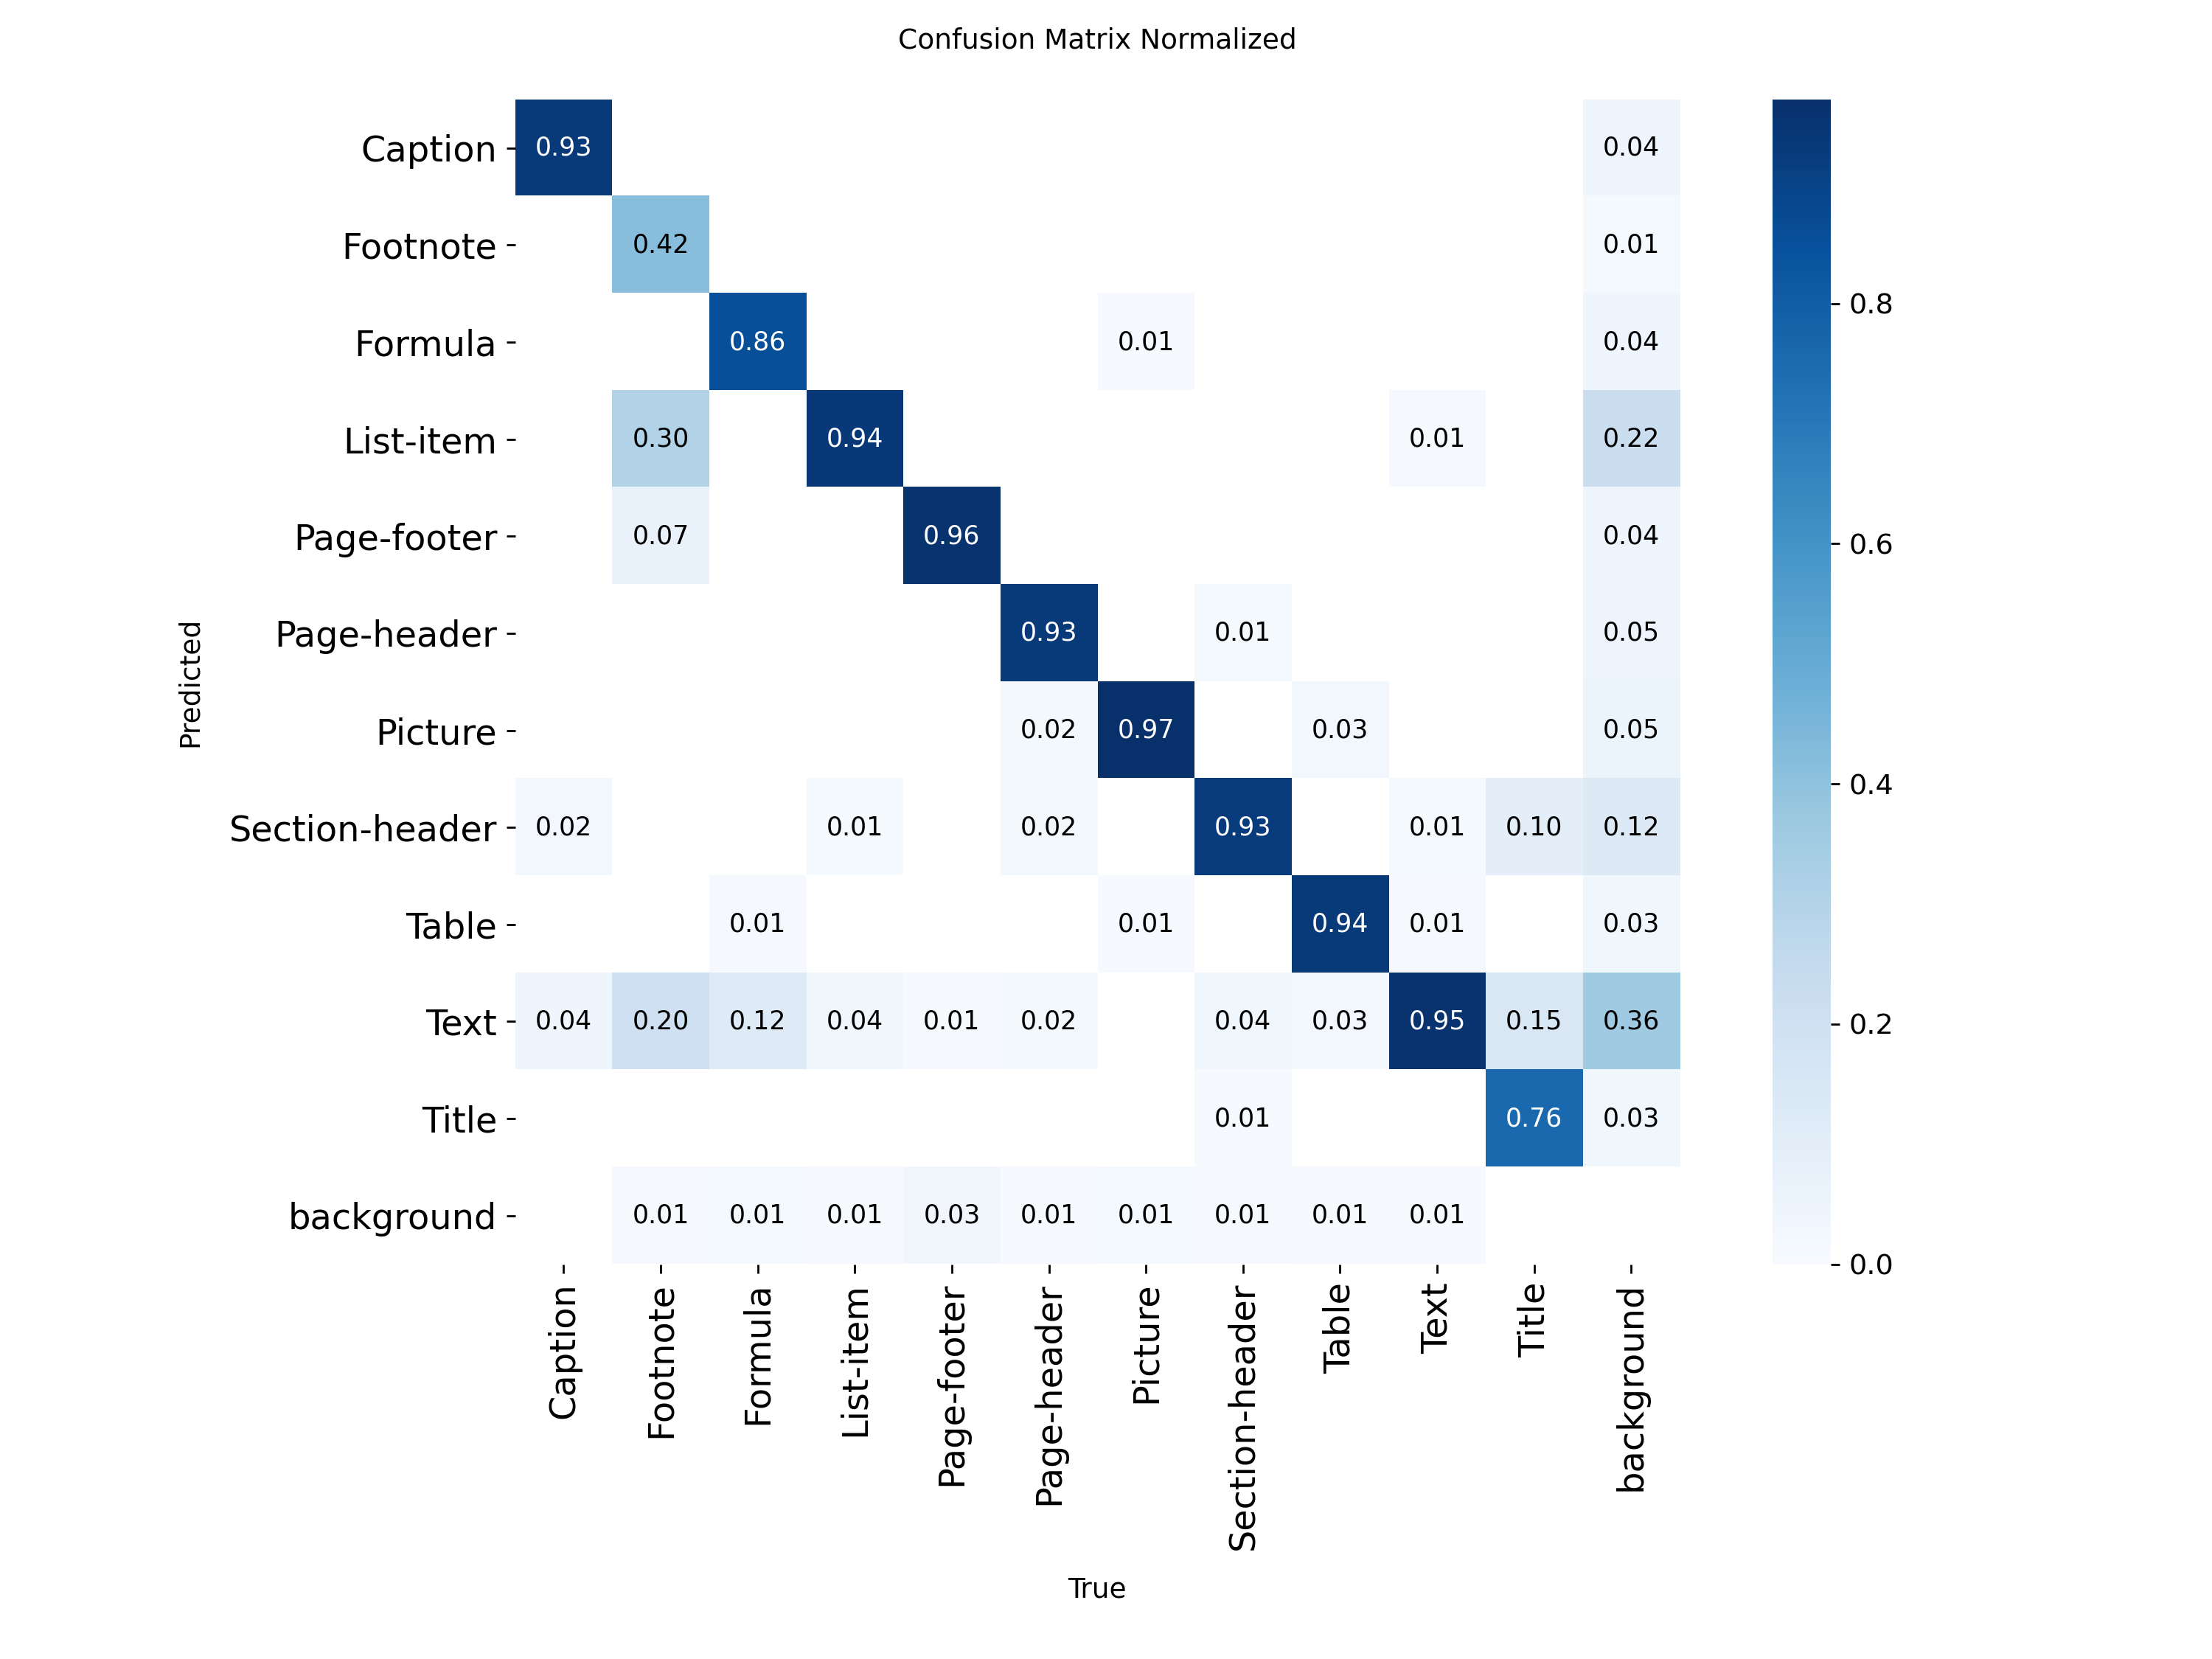

FileNotFoundError: No such file or directory: '/kaggle/working/runs/eval_val/PR_curve.png'

FileNotFoundError: No such file or directory: '/kaggle/working/runs/eval_val/PR_curve.png'

<IPython.core.display.Image object>

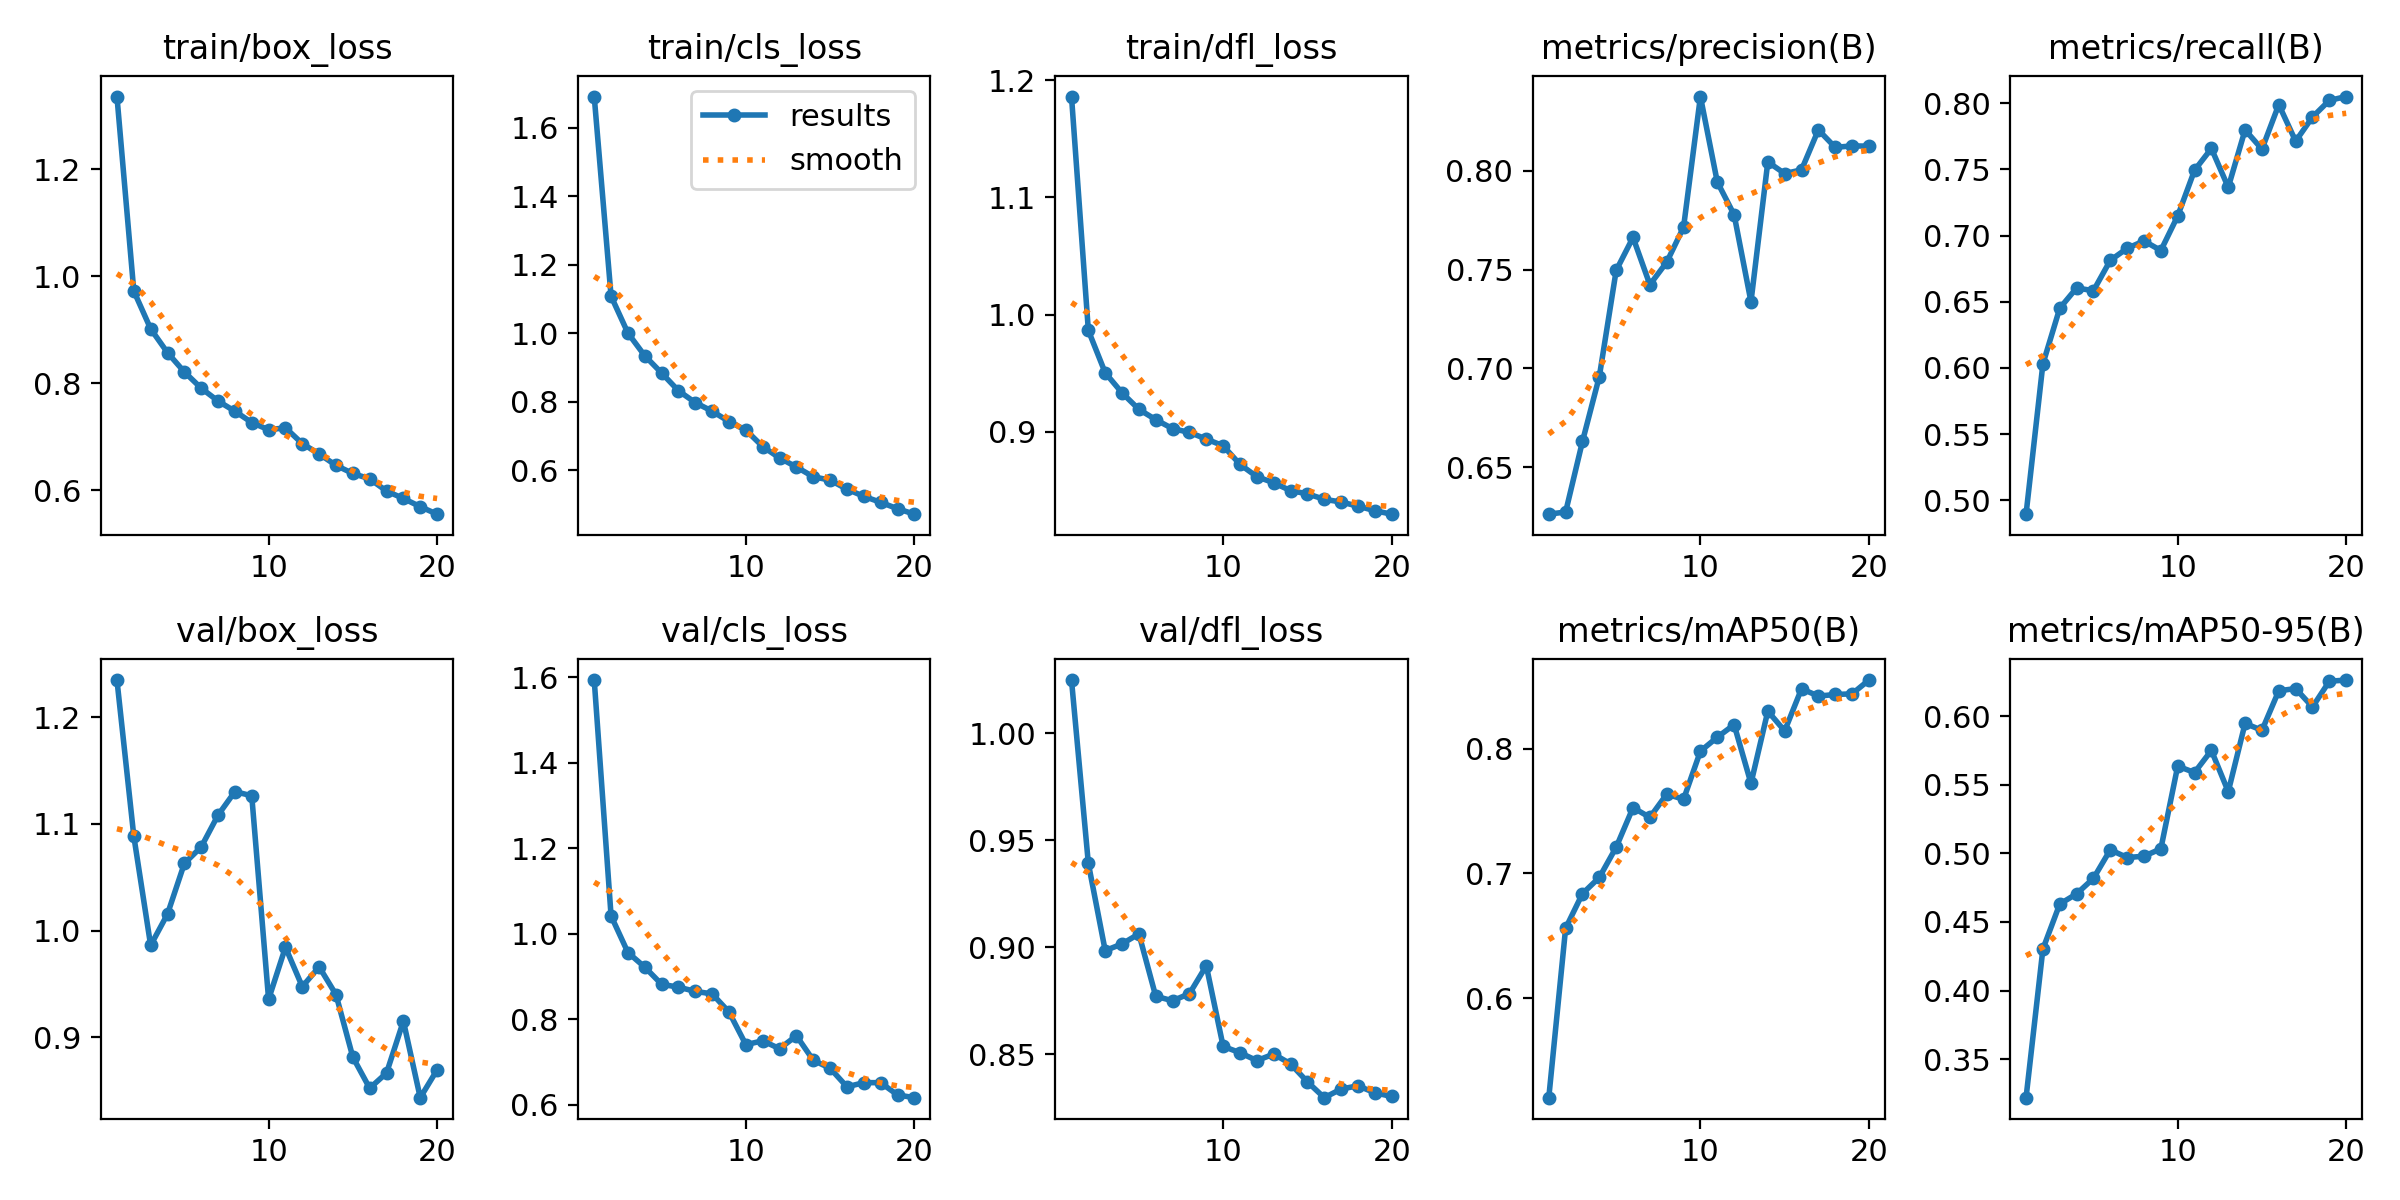

In [18]:
import pandas as pd
from IPython.display import Image, display

best = YOLO("/kaggle/working/runs/baseline/weights/best.pt")
m = best.val(
    data=str(OUT / "data.yaml"), imgsz=640, device=0, plots=True,
    project="/kaggle/working/runs", name="eval_val", exist_ok=True,
)

print(f"mAP50: {m.box.map50:.3f}   mAP50-95: {m.box.map:.3f}   "
      f"P: {m.box.mp:.3f}   R: {m.box.mr:.3f}")

rows = []
for i, c in enumerate(m.box.ap_class_index):
    rows.append({
        "class": NAMES[c],
        "instances": int(m.nt_per_class[c]),
        "precision": round(float(m.box.p[i]), 3),
        "recall": round(float(m.box.r[i]), 3),
        "AP50": round(float(m.box.ap50[i]), 3),
        "AP50-95": round(float(m.box.ap[i]), 3),
    })
table = pd.DataFrame(rows).sort_values("AP50-95")
table.to_csv("/kaggle/working/per_class_metrics.csv", index=False)
print(table.to_string(index=False))
print("Speed (ms/image):", m.speed)

for f in ["confusion_matrix_normalized.png", "PR_curve.png"]:
    display(Image(f"/kaggle/working/runs/eval_val/{f}"))
display(Image("/kaggle/working/runs/baseline/results.png"))

## Qualitative examples

In [19]:
import random

val_imgs = random.sample(sorted((OUT / "images" / "val").glob("*.png")), 6)
best.predict(
    val_imgs, imgsz=640, conf=0.25, device=0, save=True,
    project="/kaggle/working/runs", name="preds", exist_ok=True,
)
for p in sorted(Path("/kaggle/working/runs/preds").glob("*.png")):
    display(Image(str(p), width=600))


0: 640x640 1 Page-footer, 1 Section-header, 7 Texts, 16.5ms
1: 640x640 11 Texts, 16.5ms
2: 640x640 1 Page-footer, 1 Page-header, 1 Section-header, 8 Texts, 16.5ms
3: 640x640 1 Page-footer, 2 Page-headers, 6 Section-headers, 13 Texts, 16.5ms
4: 640x640 1 Page-footer, 2 Page-headers, 1 Section-header, 9 Texts, 16.5ms
5: 640x640 1 Caption, 1 Page-footer, 1 Table, 16.5ms
Speed: 2.7ms preprocess, 16.5ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /kaggle/working/runs/preds


## Last Cell

In [20]:
 #remove the converted dataset so it isn't saved with the version
shutil.rmtree(OUT, ignore_errors=True)
print(os.listdir("/kaggle/working"))
print(os.listdir("/kaggle/working/runs/baseline/weights"))

['per_class_metrics.csv', 'runs', '.virtual_documents', 'yolov8s.pt']
['epoch0.pt', 'epoch5.pt', 'epoch15.pt', 'epoch10.pt', 'last.pt', 'best.pt']
